# 03 — D-Fire Veri Seti Keşifsel Analizi (EDA)

Görüntü modeli için kullanılan D-Fire verisinin yapısı, etiket biçimi ve sınıf dağılımı.

- Etiketler YOLO biçimindedir: `sınıf x_merkez y_merkez genişlik yükseklik` (0–1 arası).
- **Sınıf numaraları: 0 = duman, 1 = alev.** (04_yolo_egitim, Bölüm 3'te görselle doğrulandı.)
- Bölme: eğitim 14.153, doğrulama 3.101 görüntü; test seti D-Fire'ın resmî test bölmesidir.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

# Artık kendi Drive'ında olduğu için
base_path = '/content/drive/MyDrive/DFire'

# Eğer yukarıdaki çalışmazsa, MyDrive içinde ara
if not os.path.exists(base_path):
    print("DFire doğrudan bulunamadı, aranıyor...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'DFire' in dirs:
            base_path = os.path.join(root, 'DFire')
            print(f"Bulundu: {base_path}")
            break

print("\nDFire içeriği:")
print(os.listdir(base_path))


DFire içeriği:
['data']


In [6]:
import os

# base_path'i tanımla
base_path = '/content/drive/MyDrive/DFire/data'  # veya bulduğun yol

# Train klasörüne bak
train_path = os.path.join(base_path, 'train')
print("Train klasörü içeriği:")
print(os.listdir(train_path))

# Kaç görüntü var?
img_dir = os.path.join(train_path, 'images')
img_count = len(os.listdir(img_dir))
print(f"\nTrain görüntü sayısı: {img_count}")

# İlk 5 görüntünün adı
print("\nİlk 5 görüntü:")
print(sorted(os.listdir(img_dir))[:5])

Train klasörü içeriği:
['labels', 'images']

Train görüntü sayısı: 14153

İlk 5 görüntü:
['AoF00000.jpg', 'AoF00001.jpg', 'AoF00002.jpg', 'AoF00003.jpg', 'AoF00004.jpg']


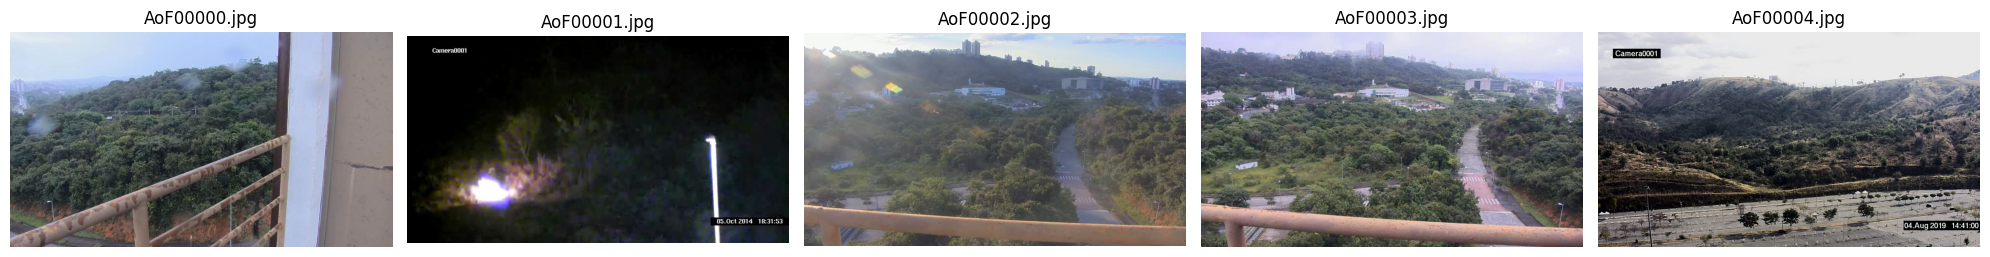

5 örnek görüntü gösterildi!


In [7]:
import matplotlib.pyplot as plt
from PIL import Image

# İlk 5 görüntüyü göster
img_files = sorted(os.listdir(img_dir))[:5]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, img_file in enumerate(img_files):
    img_path = os.path.join(img_dir, img_file)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(img_file[:15])  # İlk 15 karakter
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('ornek_goruntuler.png')
plt.show()
print("5 örnek görüntü gösterildi!")

In [8]:
import os

# Labels klasörü
label_dir = os.path.join(base_path, 'train', 'labels')
label_files = sorted(os.listdir(label_dir))

# İlk 5 etiket dosyasını oku
for label_file in label_files[:5]:
    label_path = os.path.join(label_dir, label_file)
    with open(label_path, 'r') as f:
        lines = f.readlines()
        print(f"\n{label_file}: {len(lines)} kutu")
        for line in lines[:2]:  # İlk 2 satır
            print(f"  {line.strip()}")


AoF00000.txt: 0 kutu

AoF00001.txt: 1 kutu
  1 0.21622846781504987 0.7391304347826086 0.13689936536718042 0.1505016722408027

AoF00002.txt: 1 kutu
  0 0.7672493100275989 0.2889072847682119 0.03679852805887764 0.054635761589403975

AoF00003.txt: 0 kutu

AoF00004.txt: 0 kutu


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# D-Fire etiketleri: 0 = duman, 1 = alev (04_yolo_egitim, Bölüm 3'te görselle doğrulandı)
SINIF_ADI = {0: 'duman', 1: 'alev'}

# Kutu içeren bir görüntü ve etiketi
img_file = 'AoF00001.jpg'   # AoF00000'da kutu yok; 1 kutulu görüntü seçildi
label_file = 'AoF00001.txt'

img_path = os.path.join(base_path, 'train', 'images', img_file)
label_path = os.path.join(base_path, 'train', 'labels', label_file)

# Görüntüyü aç
img = Image.open(img_path)
width, height = img.size

# Etiketi oku
with open(label_path, 'r') as f:
    lines = f.readlines()

# Çiz
fig, ax = plt.subplots(1, figsize=(10, 8))
ax.imshow(img)

for line in lines:
    parts = line.strip().split()
    class_id = int(parts[0])
    x_center, y_center, w, h = map(float, parts[1:])

    # Normalize koordinatları piksele çevir
    x = x_center * width
    y = y_center * height
    box_w = w * width
    box_h = h * height

    # Kutu çiz
    rect = patches.Rectangle((x - box_w/2, y - box_h/2), box_w, box_h,
                             linewidth=2, edgecolor='red', facecolor='none')
    ax.add_patch(rect)
    ax.text(x, y, SINIF_ADI[class_id], color='white', fontsize=12,
            bbox=dict(facecolor='red', alpha=0.5))

plt.title(f'{img_file} - {len(lines)} kutu')
plt.axis('off')
plt.savefig('kutu_cizim.png')
plt.show()

In [ ]:
import os
from collections import Counter

label_dir = os.path.join(base_path, 'train', 'labels')
label_files = os.listdir(label_dir)

# Sınıf sayacı
class_counts = Counter()
total_boxes = 0

for label_file in label_files:
    with open(os.path.join(label_dir, label_file), 'r') as f:
        lines = f.readlines()
        total_boxes += len(lines)
        for line in lines:
            class_id = int(line.strip().split()[0])
            class_counts[class_id] += 1

print("Sınıf Dağılımı (Train Seti):")
print(f"Toplam etiket dosyası: {len(label_files)} (görüntü: {len(os.listdir(img_dir))}; etiket dosyası olmayan görüntüleri YOLO yangınsız sayar)")
print(f"Toplam kutu: {total_boxes}")
print(f"\nSınıf 0 (Duman): {class_counts[0]} kutu")
print(f"Sınıf 1 (Alev): {class_counts[1]} kutu")

# Görüntü başına ortalama kutu
print(f"\nGörüntü başına ortalama kutu: {total_boxes/len(label_files):.2f}")

Yangınlı/dumanlı görüntü sayısı: 7678


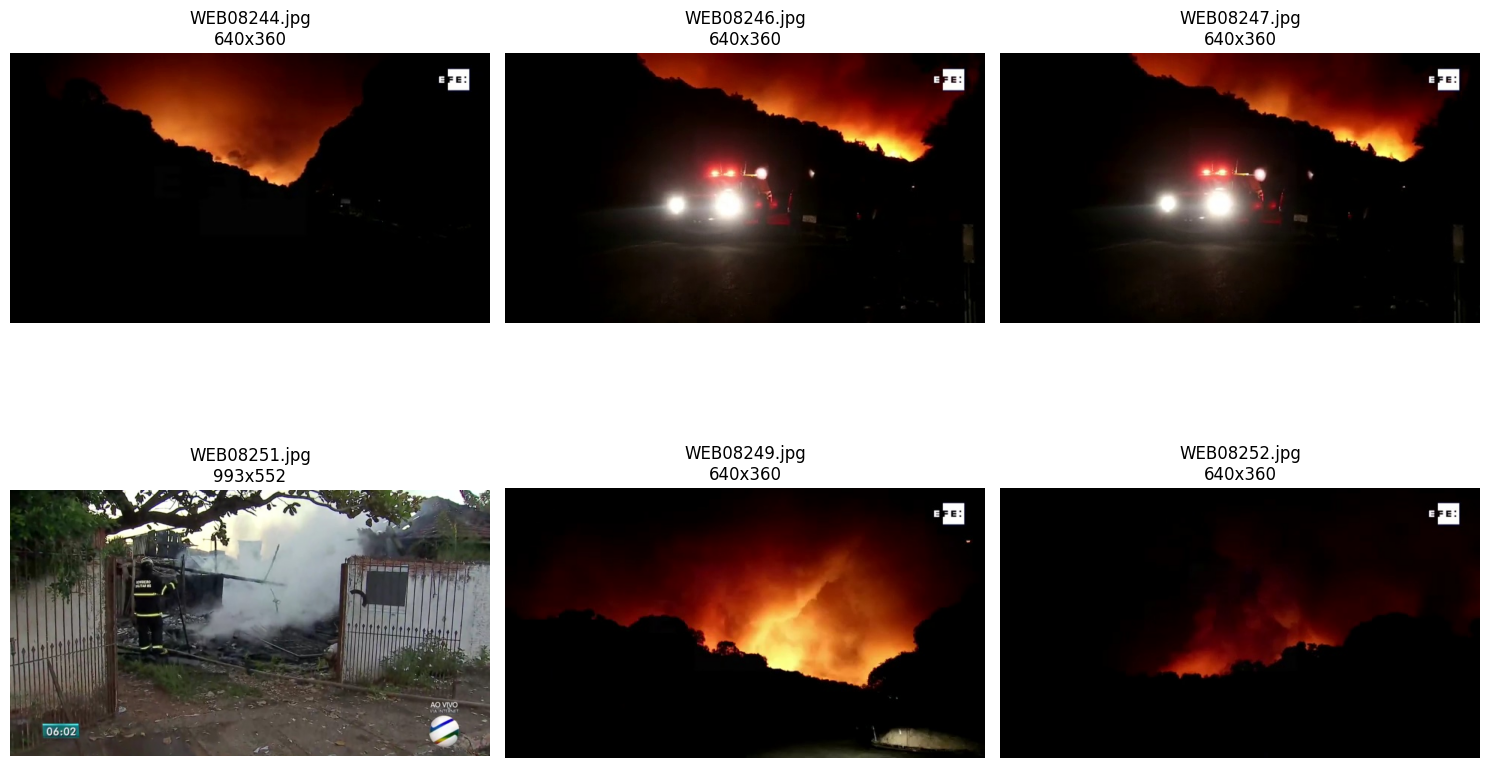

6 yangınlı örnek gösterildi!


In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Yangınlı görüntüleri bul (en az 1 kutu olanlar)
yanginli_goruntuler = []
for label_file in label_files:
    with open(os.path.join(label_dir, label_file), 'r') as f:
        if len(f.readlines()) > 0:
            yanginli_goruntuler.append(label_file.replace('.txt', '.jpg'))

print(f"Yangınlı/dumanlı görüntü sayısı: {len(yanginli_goruntuler)}")

# İlk 5 yangınlı görüntüyü göster
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i in range(6):
    if i < len(yanginli_goruntuler):
        img_file = yanginli_goruntuler[i]
        img_path = os.path.join(base_path, 'train', 'images', img_file)

        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].set_title(f'{img_file}\n{img.size[0]}x{img.size[1]}')
        axes[i].axis('off')

plt.tight_layout()
plt.savefig('yanginli_ornekler.png')
plt.show()
print("6 yangınlı örnek gösterildi!")

In [ ]:
import random

# Normal görüntülerden (0 kutulu) rastgele 6 tanesini göster
normal_goruntuler = []
for label_file in label_files:
    with open(os.path.join(label_dir, label_file), 'r') as f:
        if len(f.readlines()) == 0:  # 0 kutu = normal
            normal_goruntuler.append(label_file.replace('.txt', '.jpg'))

print(f"Normal görüntü sayısı: {len(normal_goruntuler)}")

# Rastgele 6 normal görüntü seç
random.seed(42)
secilen = random.sample(normal_goruntuler, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, img_file in enumerate(secilen):
    img_path = os.path.join(base_path, 'train', 'images', img_file)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f'Normal: {img_file[:20]}')
    axes[i].axis('off')

plt.tight_layout()
plt.savefig('normal_ornekler.png')
plt.show()
print("6 rastgele yangınsız örnek gösterildi! (Gerçek zorlu örnekler = modelin yanlış alarm verdiği görüntüler; bkz. 04_yolo_egitim, Bölüm 6)")

## Özet

- Eğitim setinde 14.153 görüntü ve 14.136 etiket dosyası var; etiket dosyası olmayan 17 görüntü YOLO tarafından yangınsız sayılır.
- 17.501 kutunun 7.806'sı duman (sınıf 0), 9.695'i alev (sınıf 1).
- Görüntülerin 7.678'inde alev ve/veya duman var, 6.458'i yangınsız; görüntü düzeyinde sınıflar yaklaşık dengeli olduğu için ek dengeleme yapılmadı.
- Görüntü başına ortalama 1,24 kutu var; bir görüntüde birden çok alev kutusu görülebiliyor.